In [120]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns
import kagglehub
from pathlib import Path
from sklearn.feature_selection import f_classif
from sklearn.model_selection import train_test_split
from sklearn.pipeline import Pipeline
from sklearn.impute import SimpleImputer
from sklearn.preprocessing import StandardScaler
from sklearn.preprocessing import OneHotEncoder
from sklearn.compose import ColumnTransformer
from sklearn.linear_model import LogisticRegression
from sklearn.metrics import accuracy_score, classification_report
from sklearn.metrics import confusion_matrix, ConfusionMatrixDisplay
from sklearn.metrics import roc_auc_score
from sklearn.svm import SVC
from sklearn.ensemble import RandomForestClassifier
from sklearn.model_selection import GridSearchCV
from sklearn.metrics import f1_score
import joblib


# Étape 1 — Chargement et Analyse exploratoire des données


## Chargement du dataset

### Download du dataset depuis Kaggle

In [58]:
dataset_path = Path(
    kagglehub.dataset_download(
        "maqdadali/mental-health-risk-prediction-dataset-students"
    )
)
print("Dataset téléchargé :", dataset_path)

Using Colab cache for faster access to the 'mental-health-risk-prediction-dataset-students' dataset.
Dataset téléchargé : /kaggle/input/mental-health-risk-prediction-dataset-students


### Identification des fichiers dans le dataset

In [59]:
for file in dataset_path.rglob("*"):
  if file.is_file():
    print(file.relative_to(dataset_path))

student_mental_health.csv
README.md


### Chargement du  CSV dans un DF



In [60]:
df = pd.read_csv(dataset_path / "student_mental_health.csv")
df.head()

,Student_ID,Age,Gender,Year_of_Study,Sleep_Hours,Study_Hours_Per_Week,GPA,Social_Media_Hours,Screen_Time_Hours,Physical_Activity,Financial_Stress,Family_Support,Attendance_Rate,Part_Time_Job,Diet_Quality,Previous_Mental_Health_History,Mental_Health_Risk
0,STU0001,22,Male,3,6.6,17.6,2.91,6.9,7.5,Moderate,8.5,4.0,78.0,No,Poor,No,High
1,STU0002,21,Male,4,5.6,22.4,2.92,7.6,11.5,Low,4.5,5.3,85.4,Yes,Average,No,Medium
2,STU0003,22,Male,5,7.1,28.1,2.68,6.5,8.9,Low,4.8,6.1,79.5,No,Average,No,Medium
3,STU0004,24,Male,1,4.5,14.8,2.23,5.5,7.6,High,3.7,8.0,73.9,No,Average,Yes,High
4,STU0005,20,Female,1,6.7,17.2,2.69,4.3,7.0,Moderate,8.0,7.4,99.8,Yes,NaN,No,Medium


### Analyse du dataset

In [61]:
df.shape

(2000, 17)

In [62]:
df.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 2000 entries, 0 to 1999
Data columns (total 17 columns):
 #   Column                          Non-Null Count  Dtype  
---  ------                          --------------  -----  
 0   Student_ID                      2000 non-null   object 
 1   Age                             2000 non-null   int64  
 2   Gender                          2000 non-null   object 
 3   Year_of_Study                   2000 non-null   int64  
 4   Sleep_Hours                     1938 non-null   float64
 5   Study_Hours_Per_Week            2000 non-null   float64
 6   GPA                             1962 non-null   float64
 7   Social_Media_Hours              1942 non-null   float64
 8   Screen_Time_Hours               2000 non-null   float64
 9   Physical_Activity               2000 non-null   object 
 10  Financial_Stress                1909 non-null   float64
 11  Family_Support                  1946 non-null   float64
 12  Attendance_Rate                 19

In [63]:
df.describe().T

,count,mean,std,min,25%,50%,75%,max
Age,2000.0,21.131500,2.139275,17.0,20.000,21.00,23.00,29.00
Year_of_Study,2000.0,2.630000,1.316802,1.0,1.000,2.00,4.00,5.00
Sleep_Hours,1938.0,6.758875,1.127072,3.3,6.000,6.70,7.60,10.00
Study_Hours_Per_Week,2000.0,19.997900,5.719274,2.4,16.000,19.80,24.00,38.30
GPA,1962.0,2.562503,0.343993,1.5,2.320,2.56,2.79,3.66
Social_Media_Hours,1942.0,6.013955,1.153422,2.1,5.225,6.00,6.70,10.00
Screen_Time_Hours,2000.0,8.548500,1.657571,3.3,7.400,8.50,9.70,14.00
Financial_Stress,1909.0,5.956260,1.893941,1.4,4.500,6.10,7.40,10.00
Family_Support,1946.0,6.518345,1.844639,1.7,5.100,6.70,8.00,9.90
Attendance_Rate,1953.0,85.080236,7.224118,54.4,80.300,85.10,90.00,100.00


In [64]:
df.isna().sum()

,0
Student_ID,0
Age,0
Gender,0
Year_of_Study,0
Sleep_Hours,62
Study_Hours_Per_Week,0
GPA,38
Social_Media_Hours,58
Screen_Time_Hours,0
Physical_Activity,0


In [65]:
df.duplicated().sum()

np.int64(0)

In [66]:
df.dropna().shape

(1606, 17)

### Variables catégorielles

In [67]:
categ_col = df.select_dtypes(include="object").columns

for col in categ_col :
  print(f"\n{col}")
  print(df[col].value_counts(dropna=False))


Student_ID
Student_ID
STU0001    1
STU0002    1
STU0003    1
STU0004    1
STU0005    1
          ..
STU1996    1
STU1997    1
STU1998    1
STU1999    1
STU2000    1
Name: count, Length: 2000, dtype: int64

Gender
Gender
Female        971
Male          932
Non-binary     97
Name: count, dtype: int64

Physical_Activity
Physical_Activity
Moderate    906
Low         679
High        415
Name: count, dtype: int64

Part_Time_Job
Part_Time_Job
No     1289
Yes     711
Name: count, dtype: int64

Diet_Quality
Diet_Quality
Average    860
Poor       587
Good       484
NaN         69
Name: count, dtype: int64

Previous_Mental_Health_History
Previous_Mental_Health_History
No     1408
Yes     592
Name: count, dtype: int64

Mental_Health_Risk
Mental_Health_Risk
High      680
Medium    660
Low       660
Name: count, dtype: int64


### Valeurs aberrantes

([0, 1, 2, 3, 4, 5, 6, 7, 8, 9],
 [Text(0, 0, 'Age'),
  Text(1, 0, 'Year_of_Study'),
  Text(2, 0, 'Sleep_Hours'),
  Text(3, 0, 'Study_Hours_Per_Week'),
  Text(4, 0, 'GPA'),
  Text(5, 0, 'Social_Media_Hours'),
  Text(6, 0, 'Screen_Time_Hours'),
  Text(7, 0, 'Financial_Stress'),
  Text(8, 0, 'Family_Support'),
  Text(9, 0, 'Attendance_Rate')])

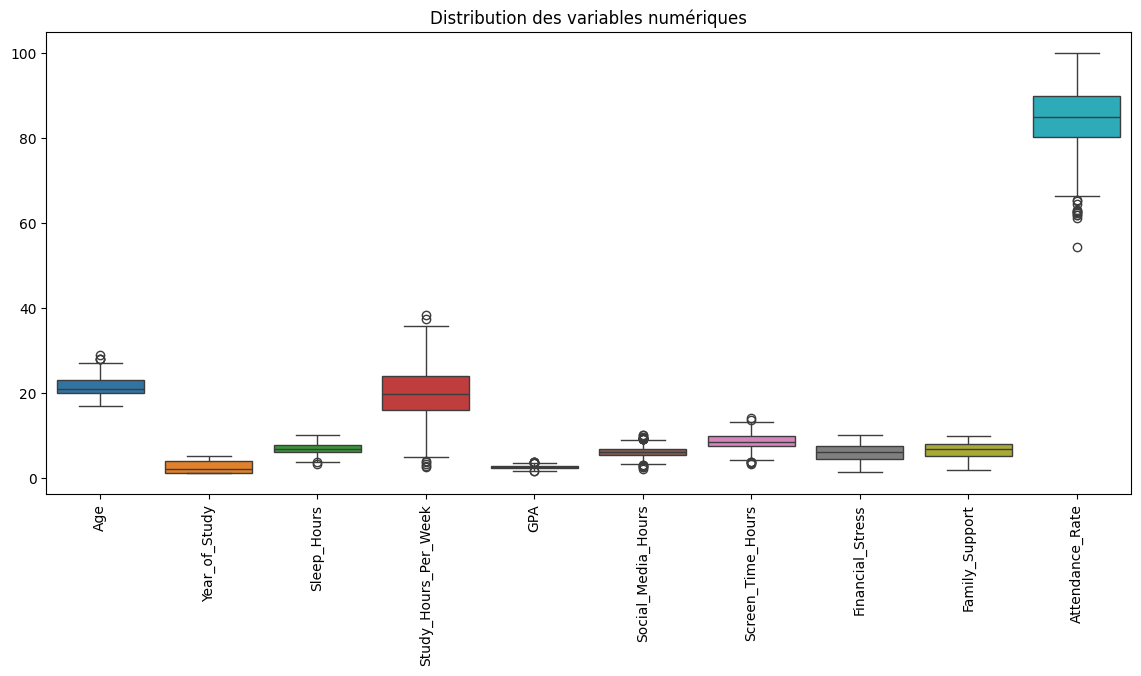

In [68]:
num_col = df.select_dtypes(include="number").columns

plt.figure(figsize=(14,6))
sns.boxplot(data= df[num_col])
plt.title("Distribution des variables numériques")
plt.xticks(rotation=90)

In [69]:
Q1 = df[num_col].quantile(0.25)
Q3 = df[num_col].quantile(0.75)

IQR = Q3 - Q1

outliers = (
    (df[num_col] < (Q1 - 1.5 * IQR)) |
    (df[num_col] > (Q3 + 1.5 * IQR))
)

outliers.sum()

,0
Age,4
Year_of_Study,0
Sleep_Hours,2
Study_Hours_Per_Week,7
GPA,9
Social_Media_Hours,20
Screen_Time_Hours,7
Financial_Stress,0
Family_Support,0
Attendance_Rate,12


### Vérification des incohérences

In [70]:
df[num_col].agg(["min", "max"]).T

,min,max
Age,17.0,29.00
Year_of_Study,1.0,5.00
Sleep_Hours,3.3,10.00
Study_Hours_Per_Week,2.4,38.30
GPA,1.5,3.66
Social_Media_Hours,2.1,10.00
Screen_Time_Hours,3.3,14.00
Financial_Stress,1.4,10.00
Family_Support,1.7,9.90
Attendance_Rate,54.4,100.00


### Répartition de la cible

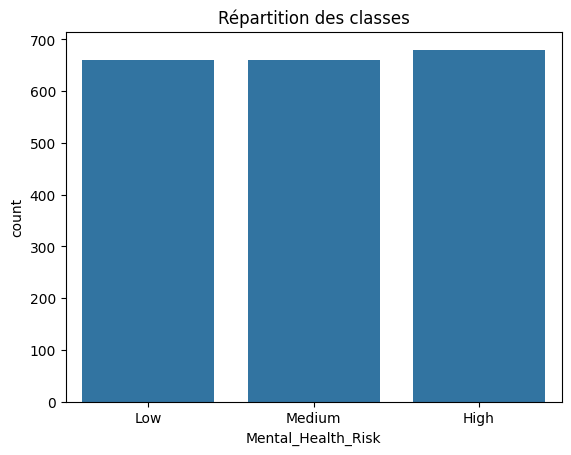

In [71]:
sns.countplot(
    data = df,
    x="Mental_Health_Risk",
    order=["Low", "Medium", "High"]
)

plt.title("Répartition des classes")
plt.show()

### Distribution des variables num

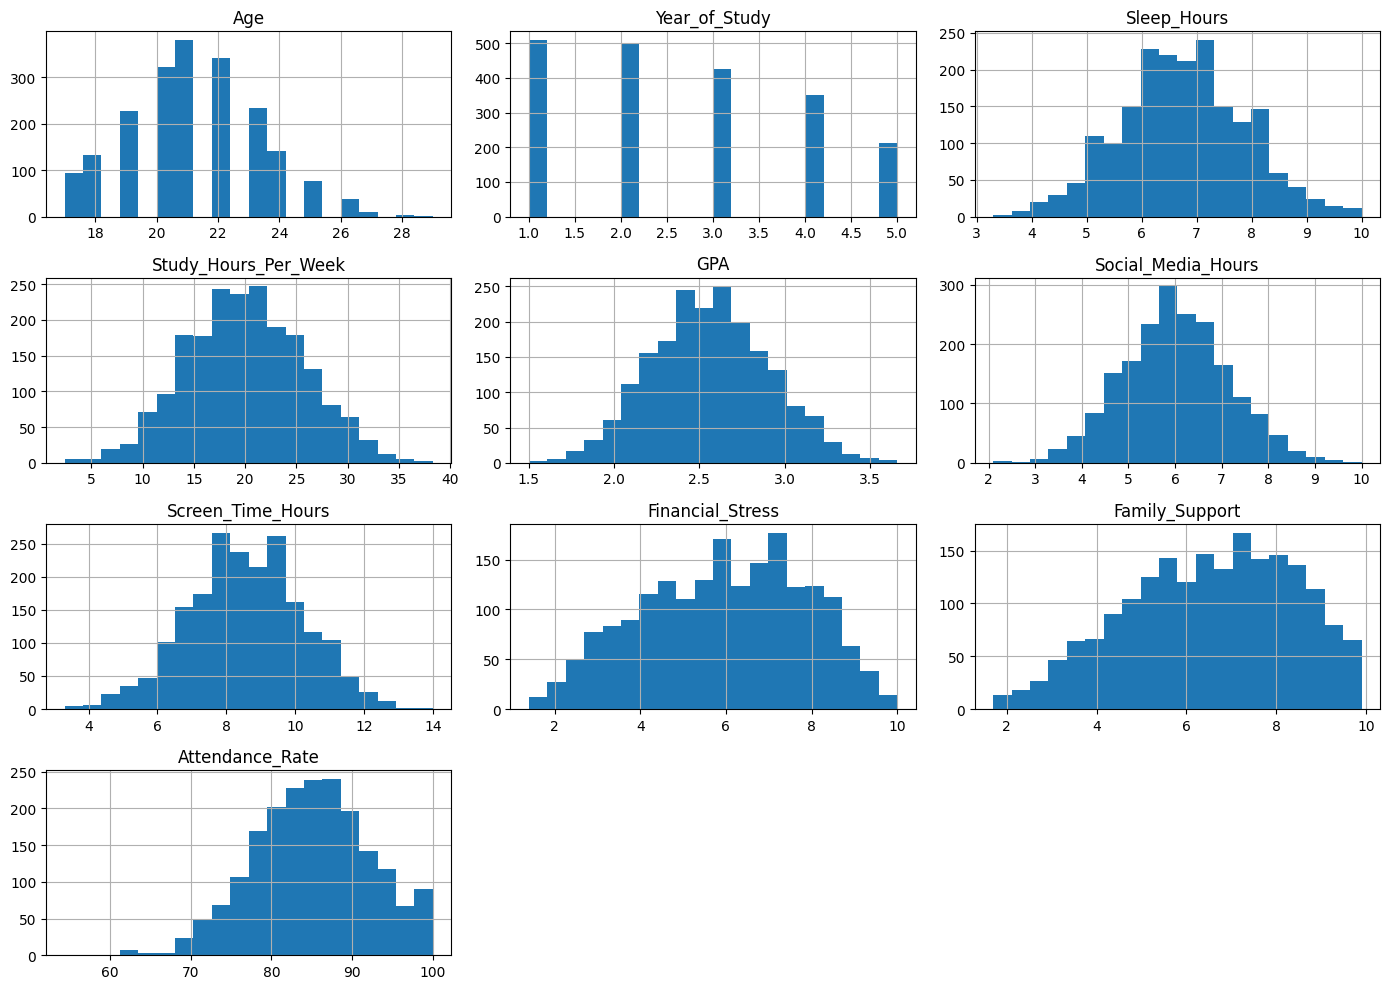

In [72]:
df[num_col].hist(figsize=(14, 10), bins=20)
plt.tight_layout()
plt.show()

### Matrice de corrélation


In [73]:
correlation = df[num_col].corr()

Text(0.5, 1.0, 'Corrélation des variables numériques')

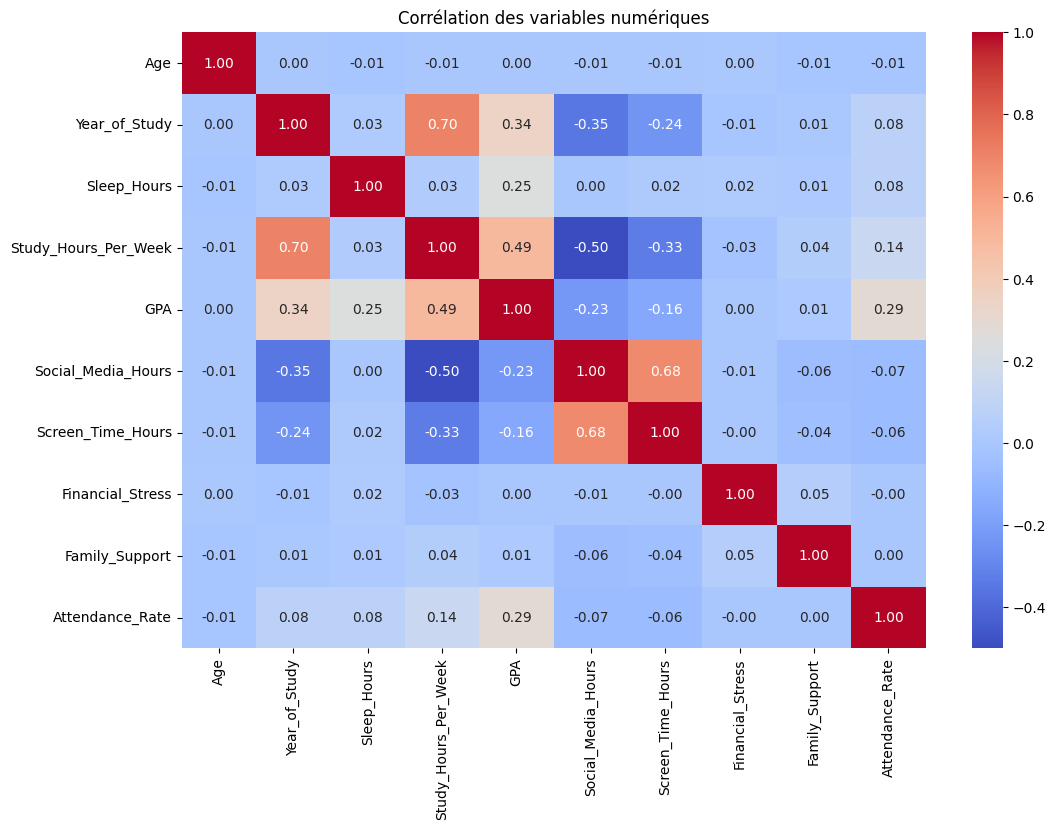

In [74]:
plt.figure(figsize=(12,8))

sns.heatmap(
    correlation,
    annot = True,
    fmt = ".2f",
    cmap = "coolwarm"
)
plt.title("Corrélation des variables numériques")


### Analyse bivariée

#### Mental_Health_Risk et Sleep_Hours

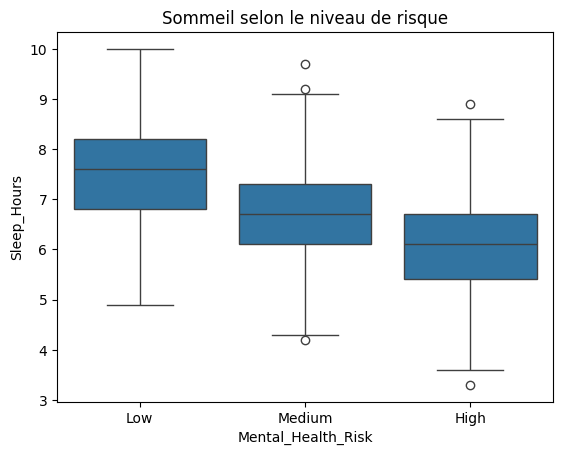

In [75]:
sns.boxplot(
    data=df,
    x="Mental_Health_Risk",
    y="Sleep_Hours",
    order=["Low", "Medium", "High"]
)

plt.title("Sommeil selon le niveau de risque")
plt.show()

#### Mental_Health_Risk et Financial_Stress

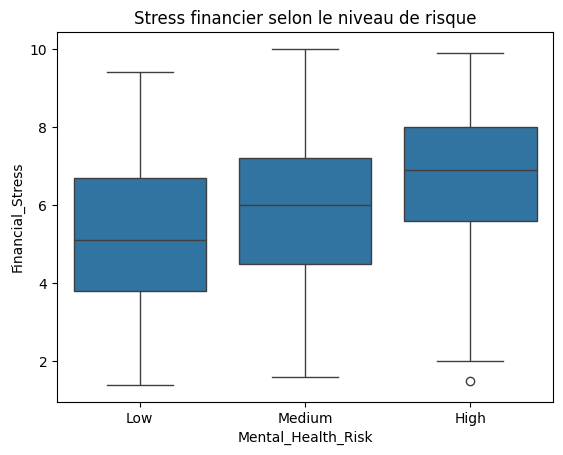

In [76]:
sns.boxplot(
    data=df,
    x="Mental_Health_Risk",
    y="Financial_Stress",
    order=["Low", "Medium", "High"]
)

plt.title("Stress financier selon le niveau de risque")
plt.show()

#### Mental_Health_Risk et Family_Support

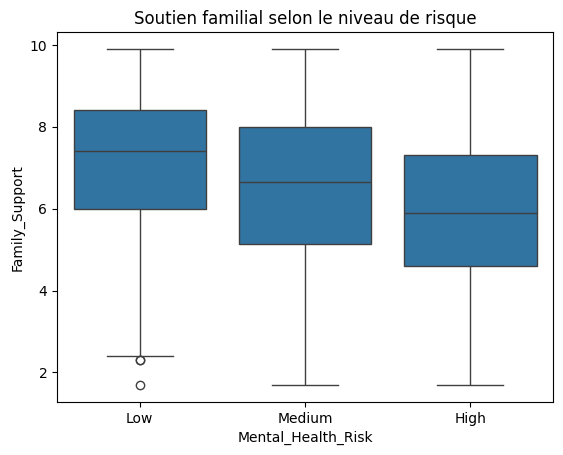

In [77]:
sns.boxplot(
    data=df,
    x="Mental_Health_Risk",
    y="Family_Support",
    order=["Low", "Medium", "High"]
)

plt.title("Soutien familial selon le niveau de risque")
plt.show()

#### Mental_Health_Risk et Social_Media_Hours

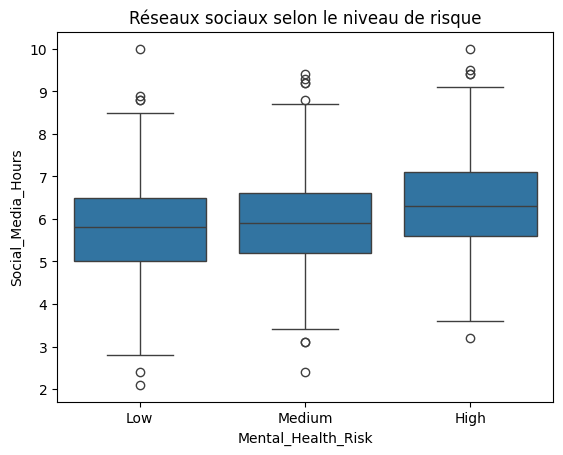

In [78]:
sns.boxplot(
    data=df,
    x="Mental_Health_Risk",
    y="Social_Media_Hours",
    order=["Low", "Medium", "High"]
)

plt.title("Réseaux sociaux selon le niveau de risque")
plt.show()

#### Mental_Health_Risk et Physical_Activity

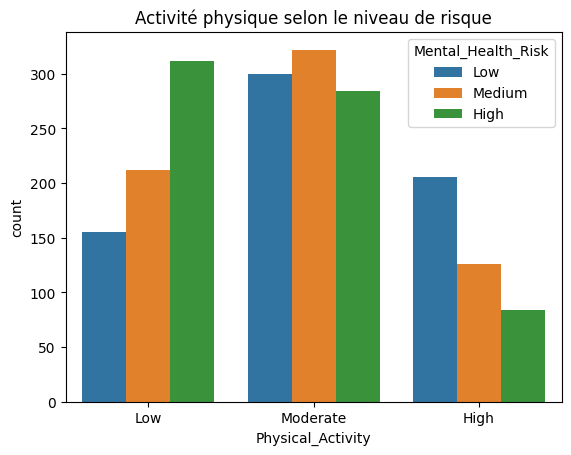

In [79]:
sns.countplot(
    data=df,
    x="Physical_Activity",
    hue="Mental_Health_Risk",
    order=["Low", "Moderate", "High"],
    hue_order=["Low", "Medium", "High"]
)

plt.title("Activité physique selon le niveau de risque")
plt.show()

#### Mental_Health_Risk et Diet_Quality

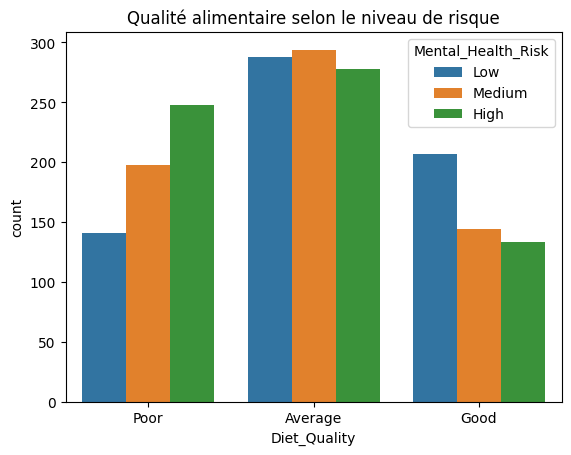

In [80]:
sns.countplot(
    data=df,
    x="Diet_Quality",
    hue="Mental_Health_Risk",
    order=["Poor", "Average", "Good"],
    hue_order=["Low", "Medium", "High"]
)

plt.title("Qualité alimentaire selon le niveau de risque")
plt.show()

#### Mental_Health_Risk et Previous_Mental_Health_History

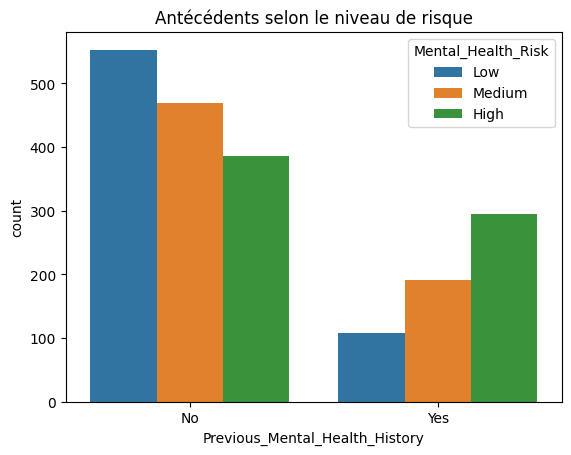

In [81]:
sns.countplot(
    data=df,
    x="Previous_Mental_Health_History",
    hue="Mental_Health_Risk",
    hue_order=["Low", "Medium", "High"]
)

plt.title("Antécédents selon le niveau de risque")
plt.show()

### Relation avec la cible

In [82]:
X = df.select_dtypes(include="number")
y = df["Mental_Health_Risk"]

X = X.fillna(X.median())

scores, p_values = f_classif(X,y)
pd.Series(scores, index=X.columns).sort_values(ascending=False)

,0
Sleep_Hours,401.445191
GPA,139.402007
Financial_Stress,103.854541
Family_Support,64.944338
Study_Hours_Per_Week,60.398872
Social_Media_Hours,46.769452
Screen_Time_Hours,34.361539
Year_of_Study,28.464648
Attendance_Rate,21.106324
Age,0.041567


# Étape 2 — Transformation et préparation des données


## Variables X et y

In [83]:
X = df.drop(columns=["Student_ID", "Mental_Health_Risk"])
y = df["Mental_Health_Risk"]

print("X :", X.shape)
print("y :", y.shape)

X : (2000, 15)
y : (2000,)


## Séparation Train/Test

In [84]:
X_train , X_test , y_train, y_test = train_test_split(
    X,
    y,
    test_size= 0.2,
    random_state= 42,
    stratify= y
)

## Variables numériques et catégorielles

In [85]:
num_cols = X_train.select_dtypes(include="number").columns
cat_cols = X_train.select_dtypes(include="object").columns

print("Variables numériques :", num_cols.tolist())
print("Variables catégorielles :", cat_cols.tolist())

Variables numériques : ['Age', 'Year_of_Study', 'Sleep_Hours', 'Study_Hours_Per_Week', 'GPA', 'Social_Media_Hours', 'Screen_Time_Hours', 'Financial_Stress', 'Family_Support', 'Attendance_Rate']
Variables catégorielles : ['Gender', 'Physical_Activity', 'Part_Time_Job', 'Diet_Quality', 'Previous_Mental_Health_History']


## Preprocessing

### Preprocessing numérique

In [86]:
num_pip = Pipeline([
    ("imputer",SimpleImputer(strategy="median")),
    ("scaler",StandardScaler())
])

### Preprocessing catégoriel

In [87]:
cat_pip = Pipeline([
    ("imputer",SimpleImputer(strategy="most_frequent")),
    ("encoder",OneHotEncoder(handle_unknown="ignore"))
])

### Combinaison des pipelines

In [88]:
preprocessor = ColumnTransformer([
    ("num",num_pip,num_cols),
    ("cat",cat_pip,cat_cols)
])

# Étape 3 — Entraînement et comparaison des modèles


## Modèle Logistic Regression

In [89]:
lr_pip = Pipeline([
    ("preprocessor" , preprocessor),
    ("logistic_reg",LogisticRegression())
])

In [90]:
lr_pip.fit(X_train,y_train)

Pipeline(steps=[('preprocessor',
                 ColumnTransformer(transformers=[('num',
                                                  Pipeline(steps=[('imputer',
                                                                   SimpleImputer(strategy='median')),
                                                                  ('scaler',
                                                                   StandardScaler())]),
                                                  Index(['Age', 'Year_of_Study', 'Sleep_Hours', 'Study_Hours_Per_Week', 'GPA',
       'Social_Media_Hours', 'Screen_Time_Hours', 'Financial_Stress',
       'Family_Support', 'Attendance_Rate'],
      dtype='object')),
                                                 ('cat',
                                                  Pipeline(steps=[('imputer',
                                                                   SimpleImputer(strategy='most_frequent')),
                                                                  ('encoder',
                                                                   OneHotEncoder(handle_unknown='ignore'))]),
                                                  Index(['Gender', 'Physical_Activity', 'Part_Time_Job', 'Diet_Quality',
       'Previous_Mental_Health_History'],
      dtype='object'))])),
                ('logistic_reg', LogisticRegression())])

In [91]:
y_pred_lr = lr_pip.predict(X_test)

### Évaluation Logistic Regression

In [92]:
print("Accuracy :", accuracy_score(y_test, y_pred_lr))
print("\nClassification Report :")
print(classification_report(y_test, y_pred_lr))


Accuracy : 0.755

Classification Report :
              precision    recall  f1-score   support

        High       0.81      0.82      0.82       136
         Low       0.82      0.81      0.81       132
      Medium       0.63      0.63      0.63       132

    accuracy                           0.76       400
   macro avg       0.75      0.75      0.75       400
weighted avg       0.75      0.76      0.75       400



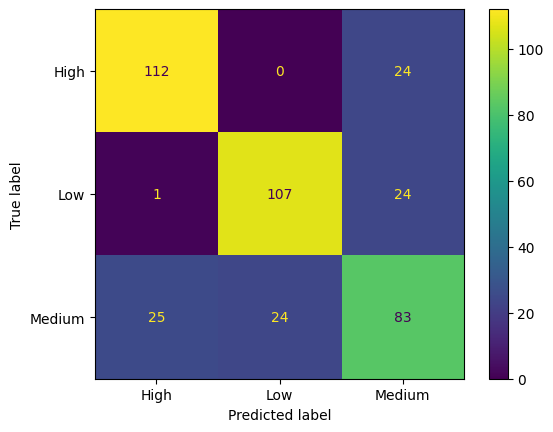

In [93]:
cm_lr = confusion_matrix(y_test,y_pred_lr)

cm = ConfusionMatrixDisplay(
    confusion_matrix = cm_lr,
    display_labels = lr_pip.classes_
    )

cm.plot()

### ROC-AUC Logistic Regression

In [94]:
y_prob_lr = lr_pip.predict_proba(X_test)

auc_lr = roc_auc_score(
    y_test,
    y_prob_lr,
    multi_class = "ovr",
    average = "macro"
)

print("ROC-AUC :", auc_lr)

ROC-AUC : 0.9139756875160737


## Modèle SVM

In [95]:
svm_pip = Pipeline([
    ("preprocessor",preprocessor),
    ("svm",SVC(probability=True))
])

In [96]:
svm_pip.fit(X_train,y_train)
y_pred_svm = svm_pip.predict(X_test)

### Évaluation SVM

In [97]:
print("Accuracy :", accuracy_score(y_test, y_pred_svm))
print("\nClassification Report :")
print(classification_report(y_test, y_pred_svm))


Accuracy : 0.7175

Classification Report :
              precision    recall  f1-score   support

        High       0.79      0.80      0.80       136
         Low       0.77      0.80      0.78       132
      Medium       0.58      0.55      0.57       132

    accuracy                           0.72       400
   macro avg       0.71      0.72      0.71       400
weighted avg       0.71      0.72      0.72       400



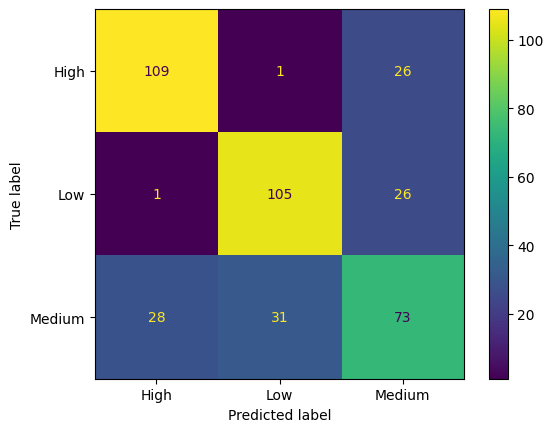

In [98]:
cm_svm = confusion_matrix(y_test,y_pred_svm)

cm = ConfusionMatrixDisplay(
    confusion_matrix = cm_svm,
    display_labels = svm_pip.classes_
)

cm.plot()

In [99]:
y_prob_svm = svm_pip.predict_proba(X_test)

auc_svm = roc_auc_score(
    y_test,
    y_prob_svm,
    multi_class = "ovr",
    average = "macro"
)
print("ROC-AUC SVM :", auc_svm)

ROC-AUC SVM : 0.8865181390285648


### Modèle Random Forest

In [100]:
rf_pip = Pipeline([
    ("preprocessor", preprocessor),
    ("random_forest", RandomForestClassifier(random_state=42))
])

In [101]:
rf_pip.fit(X_train,y_train)
y_pred_rf = rf_pip.predict(X_test)

In [102]:
print("Accuracy :", accuracy_score(y_test, y_pred_rf))
print("\nClassification Report :")
print(classification_report(y_test, y_pred_rf))

Accuracy : 0.6825

Classification Report :
              precision    recall  f1-score   support

        High       0.75      0.74      0.75       136
         Low       0.75      0.77      0.76       132
      Medium       0.54      0.54      0.54       132

    accuracy                           0.68       400
   macro avg       0.68      0.68      0.68       400
weighted avg       0.68      0.68      0.68       400



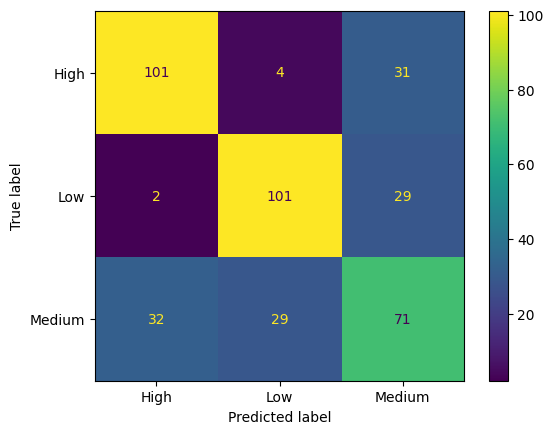

In [103]:
cm_rf = confusion_matrix(y_test, y_pred_rf)

cm = ConfusionMatrixDisplay(
    confusion_matrix=cm_rf,
    display_labels=rf_pip.classes_
)

cm.plot()


In [104]:
y_prob_rf = rf_pip.predict_proba(X_test)

auc_rf = roc_auc_score(
    y_test,
    y_prob_rf,
    multi_class="ovr",
    average="macro"
)

print("ROC-AUC Random Forest :", auc_rf)

ROC-AUC Random Forest : 0.8572407154290934


## Comparaison des modèles

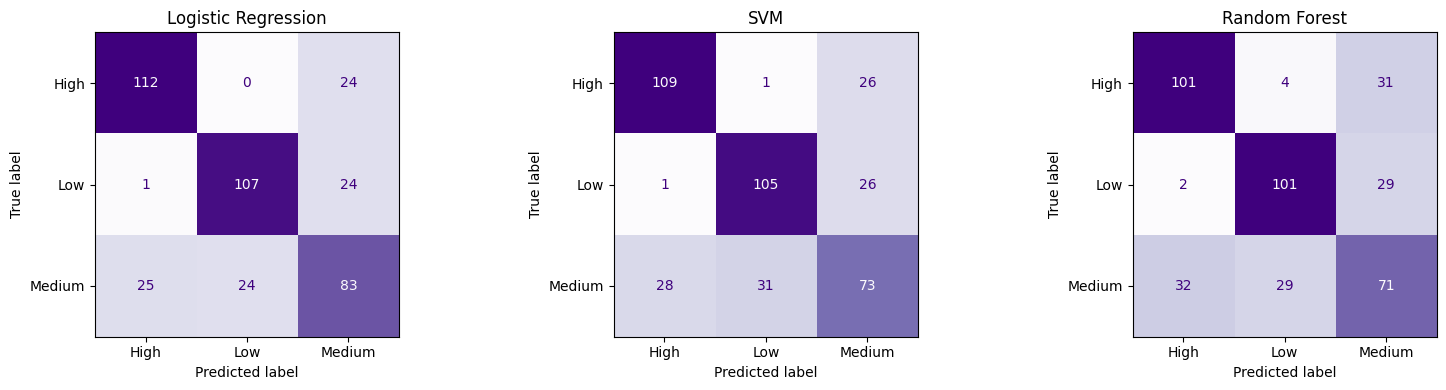

In [105]:
fig, axes = plt.subplots(1, 3, figsize=(16, 4))

models = [
    ("Logistic Regression", lr_pip),
    ("SVM", svm_pip),
    ("Random Forest", rf_pip)
]

for ax, (name, model) in zip(axes, models):
    ConfusionMatrixDisplay.from_estimator(
        model,
        X_test,
        y_test,
        cmap="Purples",
        ax=ax,
        colorbar=False
    )
    ax.set_title(name)

plt.tight_layout()
plt.show()

# Étape 4 — Optimisation et évaluation


### Optimisation Logistic Regression

In [106]:
param_grid_lr = {
    "logistic_reg__C" : [0.01,0.1,1,10,100]
}

grid_lr = GridSearchCV(
    lr_pip,
    param_grid_lr,
    cv = 5,
    scoring = "f1_macro"
)

grid_lr.fit(X_train,y_train)

GridSearchCV(cv=5,
             estimator=Pipeline(steps=[('preprocessor',
                                        ColumnTransformer(transformers=[('num',
                                                                         Pipeline(steps=[('imputer',
                                                                                          SimpleImputer(strategy='median')),
                                                                                         ('scaler',
                                                                                          StandardScaler())]),
                                                                         Index(['Age', 'Year_of_Study', 'Sleep_Hours', 'Study_Hours_Per_Week', 'GPA',
       'Social_Media_Hours', 'Screen_Time_Hours', 'Financial_Stress',
       'Family_Support', 'Attendance...
                                                                         Pipeline(steps=[('imputer',
                                                                                          SimpleImputer(strategy='most_frequent')),
                                                                                         ('encoder',
                                                                                          OneHotEncoder(handle_unknown='ignore'))]),
                                                                         Index(['Gender', 'Physical_Activity', 'Part_Time_Job', 'Diet_Quality',
       'Previous_Mental_Health_History'],
      dtype='object'))])),
                                       ('logistic_reg', LogisticRegression())]),
             param_grid={'logistic_reg__C': [0.01, 0.1, 1, 10, 100]},
             scoring='f1_macro')

### Optimisation SVC

In [107]:
param_grid_svc = {
    "svm__C" : [0.01,0.1,1,10,100]
}

grid_svc = GridSearchCV(
    svm_pip,
    param_grid_svc,
    cv = 5,
    scoring = "f1_macro"
)

grid_svc.fit(X_train,y_train)

GridSearchCV(cv=5,
             estimator=Pipeline(steps=[('preprocessor',
                                        ColumnTransformer(transformers=[('num',
                                                                         Pipeline(steps=[('imputer',
                                                                                          SimpleImputer(strategy='median')),
                                                                                         ('scaler',
                                                                                          StandardScaler())]),
                                                                         Index(['Age', 'Year_of_Study', 'Sleep_Hours', 'Study_Hours_Per_Week', 'GPA',
       'Social_Media_Hours', 'Screen_Time_Hours', 'Financial_Stress',
       'Family_Support', 'Attendance...
      dtype='object')),
                                                                        ('cat',
                                                                         Pipeline(steps=[('imputer',
                                                                                          SimpleImputer(strategy='most_frequent')),
                                                                                         ('encoder',
                                                                                          OneHotEncoder(handle_unknown='ignore'))]),
                                                                         Index(['Gender', 'Physical_Activity', 'Part_Time_Job', 'Diet_Quality',
       'Previous_Mental_Health_History'],
      dtype='object'))])),
                                       ('svm', SVC(probability=True))]),
             param_grid={'svm__C': [0.01, 0.1, 1, 10, 100]},
             scoring='f1_macro')

### Comparaison après optimisation

In [108]:
print("Logistic Regression")
print("Meilleur C :",grid_lr.best_params_)
print("F1 macro CV :",grid_lr.best_score_)

print("\nSVM")
print("Meilleur C :", grid_svc.best_params_)
print("F1 macro CV :", grid_svc.best_score_)

Logistic Regression
Meilleur C : {'logistic_reg__C': 10}
F1 macro CV : 0.7532364876270358

SVM
Meilleur C : {'svm__C': 1}
F1 macro CV : 0.7088481013388981


### Sélection du meilleur modèle

In [109]:
best_model = grid_lr.best_estimator_

### Évaluation du modèle optimisé

In [110]:
y_pred_best = best_model.predict(X_test)

print("Accuracy :", accuracy_score(y_test, y_pred_best))
print("\nClassification Report :")
print(classification_report(y_test, y_pred_best))


Accuracy : 0.7525

Classification Report :
              precision    recall  f1-score   support

        High       0.81      0.82      0.82       136
         Low       0.82      0.80      0.81       132
      Medium       0.63      0.63      0.63       132

    accuracy                           0.75       400
   macro avg       0.75      0.75      0.75       400
weighted avg       0.75      0.75      0.75       400



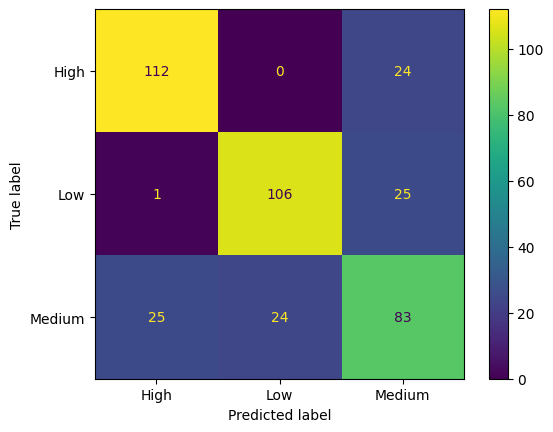

In [111]:
cm_best = confusion_matrix(y_test,y_pred_best)

cm = ConfusionMatrixDisplay(
    confusion_matrix = cm_best ,
    display_labels = best_model.classes_
)

cm.plot()

### ROC-AUC après optimisation

In [112]:
y_prob_best = best_model.predict_proba(X_test)

auc_best = roc_auc_score(
    y_test,
    y_prob_best,
    multi_class = "ovr",
    average = "macro"
)

print("ROC-AUC optimisé :", auc_best)

ROC-AUC optimisé : 0.9142019681006731


### Comparaison avant et après optimisation

In [118]:
print("F1 avant :", f1_score(y_test, y_pred_lr, average="macro"))
print("F1 après :", f1_score(y_test, y_pred_best, average="macro"))

print("ROC-AUC avant :", auc_lr)
print("ROC-AUC après :", auc_best)

F1 avant : 0.7541283894424246
F1 après : 0.751822144102191
ROC-AUC avant : 0.9139756875160737
ROC-AUC après : 0.9142019681006731


### Sauvegarde du pipeline

In [121]:
joblib.dump(best_model,"mentalrisk_model.joblib")
print("Modèle sauvegardé !")

Modèle sauvegardé !
